# 05 · Final model: multi-temporal DeepLabV3+

**Why this model.** Notebooks 02 and 03 trained nine single-month models (0.08–75 M parameters, three architectures,
four backbones). On unseen regions they all reach 0.25–0.30 test mIoU, and none beats DeepLabV3+ · ResNet50, while
the same type of model reaches 0.56–0.58 on the training regions in 2025–26. The conclusion was that **architecture is
not the bottleneck**; the main confusions (crops ↔ rangeland, bare ↔ snow/ice, trees ↔ built-up between seasons)
are between classes that differ mainly in **how they change over the year**, which a single monthly image cannot show.

**What changes: only the input.** For a target month the model sees that month **and the two previous months**
(stacked as 3 × 3 = 9 channels: VV, VH, VV−VH per month). Example: the July map is made from March + May + July.
Everything else is identical to the notebook-02 model, so a difference can be attributed to the temporal information:

| | Notebook 02 (reference) | This notebook |
|---|---|---|
| Architecture | DeepLabV3+ · ResNet50 (ImageNet) | same; the pretrained first-layer filters are copied to each month |
| Input | 1 month (3 channels) | 3 months (9 channels) |
| Data | all train regions, 2023–24 | same patches and labels (label = target month) |
| Training | AdamW 3e-4, batch 16, weighted CE + Dice, augmentation, early stopping | same |

**Fair comparison.** Both models are evaluated on exactly the same patches: those whose two previous months exist.
For the test regions the export starts in January 2025, so January and March 2025 have no earlier months and are
left out for both models. Nothing new is downloaded: the earlier months come from the existing tiles.

In [1]:
import os, shutil, subprocess
if shutil.which("nvidia-smi"):
    free = subprocess.run(["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
                          capture_output=True, text=True).stdout.split()
    os.environ["CUDA_VISIBLE_DEVICES"] = str(max(range(len(free)), key=lambda i: int(free[i])))
    print("Free GPU memory (MB):", free, "-> using GPU", os.environ["CUDA_VISIBLE_DEVICES"])
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
keras.mixed_precision.set_global_policy("mixed_float16")
keras.utils.set_random_seed(42)

from src import config as C, model as M, evaluation as E, patching as P, temporal as TM, training as T

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

Free GPU memory (MB): ['48539'] -> using GPU 0


/home/jovyan/vault/.envs/venv-lulc/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SMOKE_TEST = False     # True: 64 random patches per split, 2 epochs - only checks that the code runs

N_TIMES = TM.N_TIMES   # 3 months per input
BATCH = 16             # as in notebook 02
LR = 3e-4
MAX_EPOCHS = 2 if SMOKE_TEST else 50
PATIENCE = 8

WEIGHTS_DIR = Path(os.environ.get("LULC_WEIGHTS_DIR", ROOT / "weights"))
OUT_DIR = WEIGHTS_DIR / ("multitemporal_smoke_test" if SMOKE_TEST else "multitemporal")
OUT_DIR.mkdir(parents=True, exist_ok=True)
REFERENCE = ROOT / "weights" / "deeplabv3plus.keras"      # single-month DeepLabV3+ ResNet50 from notebook 02
stats = M.load_stats()

## 1. Multi-temporal patches

For every patch of notebooks 01/02, the same 256 × 256 window is read from the two previous exported months of the
same study area (2–3 months apart). Patches whose earlier months are missing or contain no-data pixels are dropped.

In [3]:
sizes = {}
for split in ["train", "val", "test"]:
    if not (C.PATCH_DIR / f"meta_{split}_mt{N_TIMES}.csv").exists():
        TM.build_split(split, n_times=N_TIMES)
    single = len(pd.read_csv(C.PATCH_DIR / f"meta_{split}.csv"))
    multi = pd.read_csv(C.PATCH_DIR / f"meta_{split}_mt{N_TIMES}.csv")
    sizes[split] = {"single-month patches": single, "multi-temporal patches": len(multi),
                    "kept %": round(100 * len(multi) / single, 1), "regions": multi.aoi.nunique(),
                    "target months": multi.month.nunique()}
pd.DataFrame(sizes).T

,single-month patches,multi-temporal patches,kept %,regions,target months
train,14952.0,11283.0,75.5,25.0,10.0
val,1808.0,810.0,44.8,4.0,10.0
test,4536.0,2814.0,62.0,8.0,9.0


In [4]:
def load_mt(split, cache=not SMOKE_TEST):
    # memory-mapped; on the server the training array is first copied to the fast local disk
    path = C.PATCH_DIR / f"X_{split}_mt{N_TIMES}.npy"
    if cache and Path("/tmp").exists():
        local = Path("/tmp/lulc_cache") / path.name
        if not local.exists():
            local.parent.mkdir(exist_ok=True)
            shutil.copy(path, local)
        path = local
    X = np.load(path, mmap_mode="r")
    y = np.load(C.PATCH_DIR / f"y_{split}_mt{N_TIMES}.npy", mmap_mode="r")
    meta = pd.read_csv(C.PATCH_DIR / f"meta_{split}_mt{N_TIMES}.csv")
    if SMOKE_TEST:
        idx = np.sort(np.random.default_rng(0).choice(len(X), min(64, len(X)), replace=False))
        return np.asarray(X[idx]), np.asarray(y[idx]), meta.iloc[idx].reset_index(drop=True)
    return X, y, meta

X_train, y_train, meta_train = load_mt("train")
X_val, y_val, meta_val = load_mt("val", cache=False)
X_test, y_test, meta_test = load_mt("test", cache=False)
class_weights = M.median_frequency_weights(P.class_distribution(f"train_mt{N_TIMES}").pixels)
data = dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, stats=stats, class_weights=class_weights)
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")
print("Example input months:", meta_train.input_months.iloc[0], "->", meta_train.month.iloc[0])

train (11283, 256, 256, 9) | val (810, 256, 256, 9) | test (2814, 256, 256, 9)
Example input months: 2023-01 2023-03 2023-05 -> 2023-05


## 2. Training

Identical procedure to notebook 02: augmentation (flips, rotations; brightness change drawn separately for each
month; speckle noise), weighted cross-entropy + Dice, AdamW, learning-rate halving after 3 and early stopping after 8
epochs without validation-mIoU improvement, best epoch restored.

I0000 00:00:1793995184.274848    5080 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46732 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6


deeplabv3plus_mt3: loaded from a previous run (16 epochs) - delete deeplabv3plus_mt3.keras to retrain


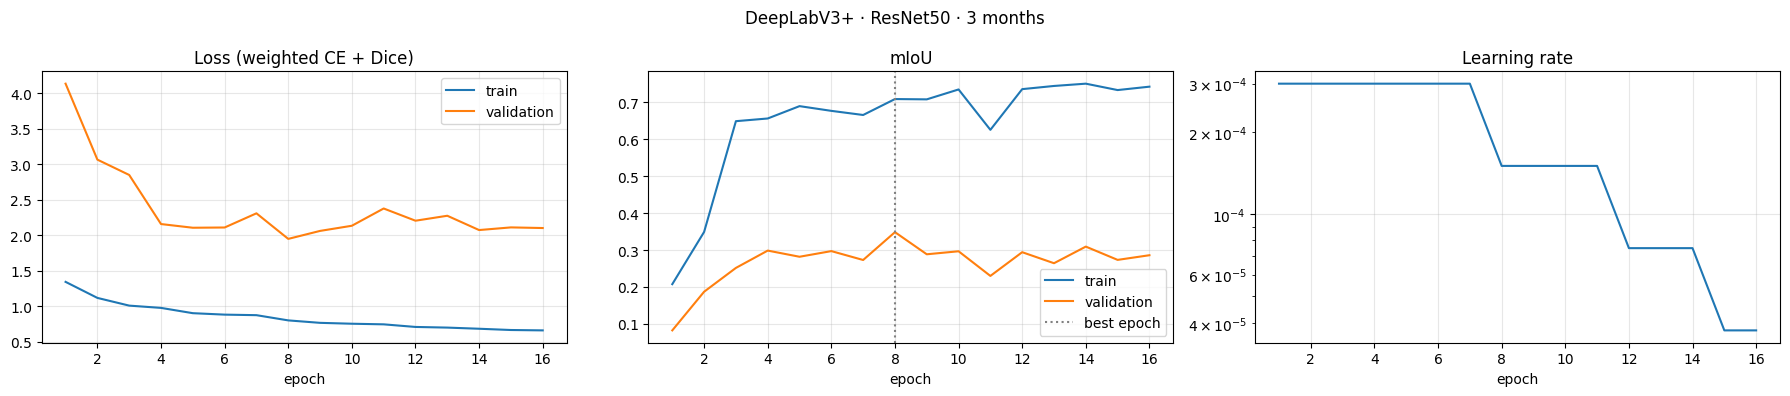

{'params': 11872712,
 'epochs_run': 16,
 'minutes': 33.2,
 'batch': 16,
 'best_epoch': 8,
 'train_mIoU': 0.7091,
 'val_mIoU': 0.3484,
 'gap': 0.3606,
 'verdict': 'overfitting: clearly better on training than on validation regions'}

In [5]:
model_mt, history_mt, info_mt = T.train_model(f"deeplabv3plus_mt{N_TIMES}", data, OUT_DIR, lr=LR, batch=BATCH,
                                              max_epochs=MAX_EPOCHS, patience=PATIENCE)
T.plot_history(history_mt, f"DeepLabV3+ · ResNet50 · {N_TIMES} months")
info_mt

## 3. Comparison with the single-month model on the same patches

The single-month model gets only the target month (the last 3 channels), the multi-temporal model all 9.

In [6]:
model_1 = keras.models.load_model(REFERENCE, compile=False)
last = slice(-len(C.S1_BANDS), None)
res = {
    "single month": {"val": T.evaluate(model_1, X_val[..., last], y_val, stats),
                     "test": T.evaluate(model_1, X_test[..., last], y_test, stats)},
    f"{N_TIMES} months": {"val": T.evaluate(model_mt, X_val, y_val, stats),
                          "test": T.evaluate(model_mt, X_test, y_test, stats)},
}
comparison = pd.DataFrame({name: {f"{split} {k}": r[split][k] for split in ["val", "test"] for k in ["OA", "mIoU", "mF1"]}
                           for name, r in res.items()}).T
comparison.loc["difference"] = comparison.iloc[1] - comparison.iloc[0]
comparison.round(4)

I0000 00:00:1793995191.346823    5228 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,val OA,val mIoU,val mF1,test OA,test mIoU,test mF1
single month,0.6153,0.3436,0.4607,0.4873,0.3132,0.4081
3 months,0.6369,0.3484,0.4721,0.4795,0.2763,0.3614
difference,0.0217,0.0048,0.0114,-0.0079,-0.0369,-0.0467


In [7]:
per_class = pd.DataFrame({
    ("IoU", "single month"): res["single month"]["test"]["per_class"]["IoU"],
    ("IoU", f"{N_TIMES} months"): res[f"{N_TIMES} months"]["test"]["per_class"]["IoU"],
    ("F1", "single month"): res["single month"]["test"]["per_class"]["F1"],
    ("F1", f"{N_TIMES} months"): res[f"{N_TIMES} months"]["test"]["per_class"]["F1"],
})
per_class[("IoU", "difference")] = per_class[("IoU", f"{N_TIMES} months")] - per_class[("IoU", "single month")]
per_class.insert(0, ("test pixels", "%"), res["single month"]["test"]["per_class"]["support_%"])
per_class.round(3)

test pixels          IoU                    F1           \
                             % single month 3 months single month 3 months   
water                    4.148        0.313    0.259        0.477    0.411   
trees                   13.009        0.517    0.322        0.682    0.487   
flooded_vegetation       0.047        0.001    0.000        0.003    0.000   
crops                   12.600        0.552    0.646        0.711    0.785   
rangeland               12.584        0.295    0.180        0.455    0.305   
built                   20.934        0.804    0.795        0.891    0.886   
bare                    22.205        0.021    0.008        0.040    0.017   
snow_ice                14.474        0.002    0.000        0.005    0.000   

                          IoU  
                   difference  
water                  -0.054  
trees                  -0.195  
flooded_vegetation     -0.001  
crops                   0.094  
rangeland              -0.115  
built                  -0.010  
bare                   -0.012  
snow_ice               -0.002

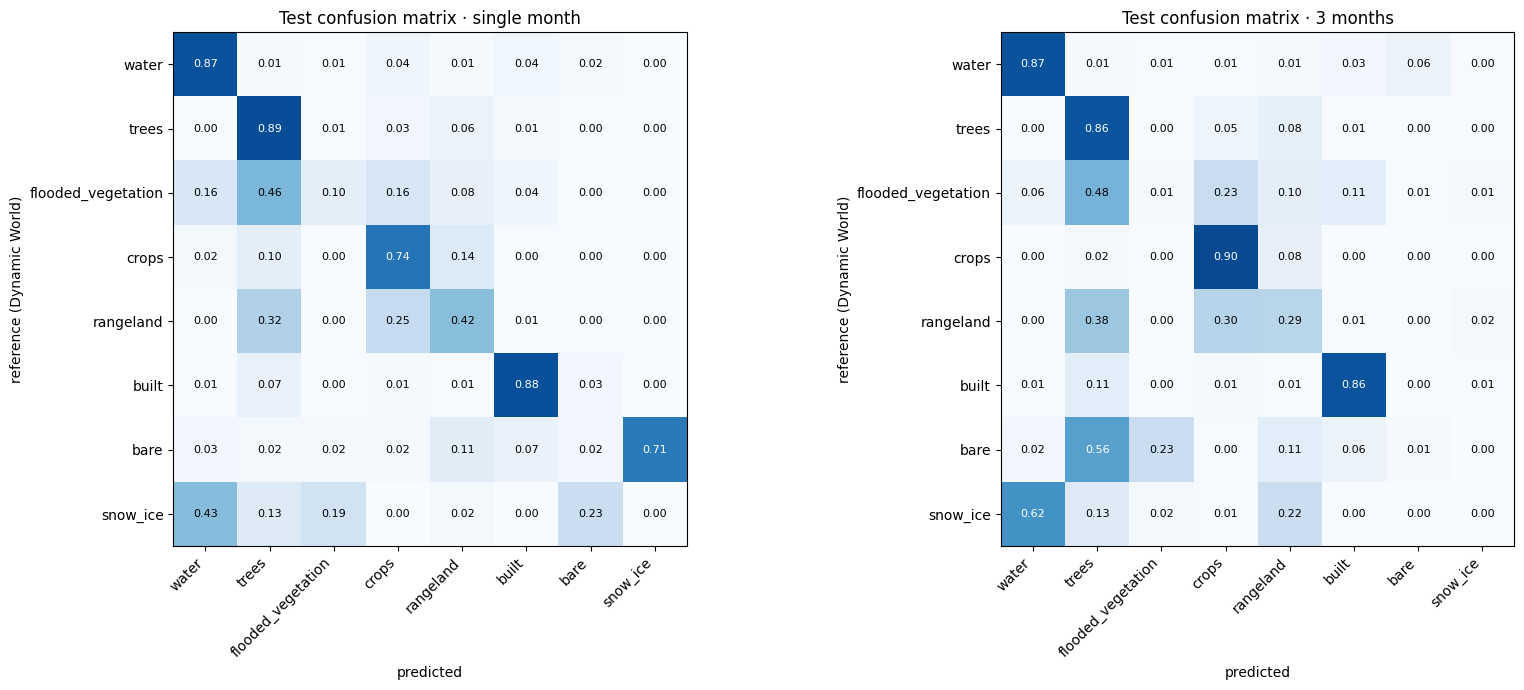

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (name, r) in zip(axes, res.items()):
    cm = r["test"]["cm"].astype(float)
    with np.errstate(invalid="ignore"):
        cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(C.CLASSES)), C.CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(C.CLASSES)), C.CLASSES)
    for i in range(len(C.CLASSES)):
        for j in range(len(C.CLASSES)):
            if np.isfinite(cmn[i, j]):
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("reference (Dynamic World)")
    ax.set_title(f"Test confusion matrix · {name}")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_single_vs_multitemporal.png", dpi=150)
plt.show()

In [9]:
def by_region(r, meta):
    rows = {}
    for aoi in sorted(meta.aoi.unique()):
        m = (meta.aoi == aoi).values
        s = E.scores(E.confusion(y_test[m], r["test"]["pred"][m]))
        rows[aoi] = (s["OA"], s["mIoU"])
    return rows

r1, r3 = by_region(res["single month"], meta_test), by_region(res[f"{N_TIMES} months"], meta_test)
regions = pd.DataFrame({"OA single": {a: v[0] for a, v in r1.items()}, f"OA {N_TIMES} months": {a: v[0] for a, v in r3.items()},
                        "mIoU single": {a: v[1] for a, v in r1.items()}, f"mIoU {N_TIMES} months": {a: v[1] for a, v in r3.items()},
                        "patches": meta_test.aoi.value_counts()})
regions["Δ OA"] = regions[f"OA {N_TIMES} months"] - regions["OA single"]
regions.round(3)

,OA single,OA 3 months,mIoU single,mIoU 3 months,patches,Δ OA
atacama_cl,0.026,0.007,0.004,0.010,513,-0.019
canterbury_nz,0.524,0.569,0.158,0.193,192,0.045
dhaka_bd,0.806,0.793,0.259,0.255,109,-0.013
dubai_ae,0.678,0.678,0.206,0.194,317,-0.001
kansas_us,0.678,0.757,0.308,0.336,442,0.079
mexico_city_mx,0.854,0.834,0.185,0.178,337,-0.020
pantanal_br,0.762,0.677,0.160,0.126,513,-0.086
vatnajokull_is,0.005,0.000,0.005,0.000,391,-0.005


## 4. Decision

Rule: the multi-temporal model would replace the single-month model in the prototype if its **validation** mIoU on the
same patches is higher, by more than the noise of the validation score (notebook 03 showed that validation mIoU varies by
about ±0.08 between epochs, and differences below that cannot separate two models).

In [10]:
val_1, val_3 = res["single month"]["val"]["mIoU"], res[f"{N_TIMES} months"]["val"]["mIoU"]
print(f"Validation mIoU: single month {val_1:.4f} | {N_TIMES} months {val_3:.4f} | difference {val_3 - val_1:+.4f}")
print("The rule selects the model with the higher validation mIoU. The difference is far below the validation noise")
print("(±0.08 between epochs), so - as for ResNet152 in notebook 03 - the simpler single-month model stays in the")
print("prototype (weights/best_model.keras); see Findings. The 3-month model is kept in", OUT_DIR)

summary = {"n_times": N_TIMES, "selected_for_prototype": "single month (validation difference within noise)",
           "training": info_mt, "comparison": comparison.round(4).to_dict(),
           "per_class_IoU": {k: v["test"]["per_class"]["IoU"].round(4).to_dict() for k, v in res.items()},
           "regions": regions.round(4).to_dict()}
_ = (OUT_DIR / "multitemporal_results.json").write_text(json.dumps(summary, indent=2, default=float))

Validation mIoU: single month 0.3436 | 3 months 0.3484 | difference +0.0048
The rule selects the model with the higher validation mIoU. The difference is far below the validation noise
(±0.08 between epochs), so - as for ResNet152 in notebook 03 - the simpler single-month model stays in the
prototype (weights/best_model.keras); see Findings. The 3-month model is kept in /home/jovyan/vault/Deep Learning project/lulc-s1/weights/multitemporal


## 5. Evaluation with radar-separable classes

All ten models (notebooks 02, 03 and this one) end up at a similar test mIoU, and their confusion matrices show where:
almost all errors fall into **two pairs of classes**:

* **bare ↔ snow/ice:** dry snow is almost transparent to C-band radar, so the sensor sees the ground below and the
  backscatter resembles bare ground; wet snow absorbs the signal and looks as dark as water.
* **crops ↔ rangeland:** in a single radar image, fields, grassland and shrubland have similar roughness and moisture.

The 8 classes come from optical maps (Dynamic World, Esri), where these pairs are easy to separate by colour. This
section evaluates the **same predictions, without retraining**, (a) with the two pairs merged into *low vegetation* and
*bare / snow* (6 classes), and (b) without the two test regions with the most extreme landscapes (Atacama salt flats,
Vatnajökull glacier), so that the effect of the class scheme and of the choice of test regions can be told apart.

In [11]:
MERGED = ["water", "trees", "flooded_vegetation", "low_vegetation", "built", "bare_snow"]
TO_MERGED = np.full(256, C.IGNORE, np.uint8)
TO_MERGED[:len(C.CLASSES)] = [0, 1, 2, 3, 3, 4, 5, 5]     # crops + rangeland, bare + snow/ice
EXTREME = ["atacama_cl", "vatnajokull_is"]


def scheme_scores(y, pred, meta):
    out = {}
    for regions, keep in [("all test regions", np.ones(len(meta), bool)),
                          ("without Atacama + Vatnajökull", ~meta.aoi.isin(EXTREME).values)]:
        yy, pp = np.asarray(y[keep]), np.asarray(pred[keep])
        out[(regions, "8 classes")] = E.scores(E.confusion(yy, pp), C.CLASSES)
        out[(regions, "6 classes")] = E.scores(E.confusion(TO_MERGED[yy], TO_MERGED[pp], n=len(MERGED)), MERGED)
    return out


# the prototype model on the full single-month test set (all 9 regions, all 11 months)
X_test_1 = np.load(C.PATCH_DIR / "X_test.npy", mmap_mode="r")
y_test_1 = np.load(C.PATCH_DIR / "y_test.npy", mmap_mode="r")
meta_test_1 = pd.read_csv(C.PATCH_DIR / "meta_test.csv")
if SMOKE_TEST:
    idx = np.sort(np.random.default_rng(0).choice(len(X_test_1), min(64, len(X_test_1)), replace=False))
    X_test_1, y_test_1, meta_test_1 = np.asarray(X_test_1[idx]), np.asarray(y_test_1[idx]), meta_test_1.iloc[idx].reset_index(drop=True)
pred_1 = T.evaluate(model_1, X_test_1, y_test_1, stats)["pred"]

schemes = {
    "single month (prototype), full test set": scheme_scores(y_test_1, pred_1, meta_test_1),
    f"{N_TIMES} months, patches with earlier months": scheme_scores(y_test, res[f"{N_TIMES} months"]["test"]["pred"], meta_test),
}
scheme_table = pd.DataFrame({(m, r, c): {"OA": s["OA"], "mIoU": s["mIoU"], "mF1": s["mF1"]}
                             for m, d in schemes.items() for (r, c), s in d.items()}).T
scheme_table.index.names = ["model", "test regions", "classes"]
scheme_table.round(3)

OA  \
model                                   test regions                  classes            
single month (prototype), full test set all test regions              8 classes  0.510   
                                                                      6 classes  0.715   
                                        without Atacama + Vatnajökull 8 classes  0.692   
                                                                      6 classes  0.772   
3 months, patches with earlier months   all test regions              8 classes  0.479   
                                                                      6 classes  0.528   
                                        without Atacama + Vatnajökull 8 classes  0.719   
                                                                      6 classes  0.791   

                                                                                  mIoU  \
model                                   test regions                  classes            
single month (prototype), full test set all test regions              8 classes  0.304   
                                                                      6 classes  0.461   
                                        without Atacama + Vatnajökull 8 classes  0.355   
                                                                      6 classes  0.459   
3 months, patches with earlier months   all test regions              8 classes  0.276   
                                                                      6 classes  0.330   
                                        without Atacama + Vatnajökull 8 classes  0.374   
                                                                      6 classes  0.469   

                                                                                   mF1  
model                                   test regions                  classes           
single month (prototype), full test set all test regions              8 classes  0.402  
                                                                      6 classes  0.585  
                                        without Atacama + Vatnajökull 8 classes  0.454  
                                                                      6 classes  0.556  
3 months, patches with earlier months   all test regions              8 classes  0.361  
                                                                      6 classes  0.424  
                                        without Atacama + Vatnajökull 8 classes  0.457  
                                                                      6 classes  0.555

In [12]:
s6 = schemes["single month (prototype), full test set"]
print("Prototype model, all test regions - 8 classes:")
display(s6[("all test regions", "8 classes")]["per_class"][["IoU", "F1", "support_%"]].round(3))
print("Prototype model, all test regions - 6 radar-separable classes:")
s6[("all test regions", "6 classes")]["per_class"][["IoU", "F1", "support_%"]].round(3)

Prototype model, all test regions - 8 classes:


,IoU,F1,support_%
water,0.364,0.534,5.200
trees,0.541,0.702,13.971
flooded_vegetation,0.004,0.008,0.082
crops,0.455,0.626,12.883
rangeland,0.269,0.424,11.075
built,0.779,0.876,24.196
bare,0.021,0.040,19.055
snow_ice,0.002,0.003,13.537


Prototype model, all test regions - 6 radar-separable classes:


,IoU,F1,support_%
water,0.364,0.534,5.200
trees,0.541,0.702,13.971
flooded_vegetation,0.004,0.008,0.082
low_vegetation,0.628,0.771,23.959
built,0.779,0.876,24.196
bare_snow,0.449,0.620,32.592


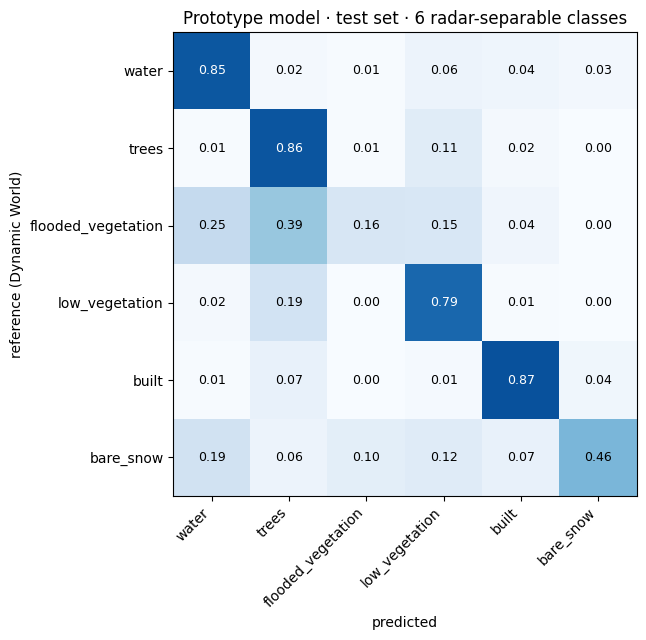

In [13]:
cm = E.confusion(TO_MERGED[np.asarray(y_test_1)], TO_MERGED[pred_1], n=len(MERGED)).astype(float)
with np.errstate(invalid="ignore"):
    cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(MERGED)), MERGED, rotation=45, ha="right")
ax.set_yticks(range(len(MERGED)), MERGED)
for i in range(len(MERGED)):
    for j in range(len(MERGED)):
        if np.isfinite(cmn[i, j]):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("reference (Dynamic World)")
ax.set_title("Prototype model · test set · 6 radar-separable classes")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_6_classes.png", dpi=150)
plt.show()

summary_path = OUT_DIR / "multitemporal_results.json"
summary = json.loads(summary_path.read_text())
summary["class_schemes"] = {" | ".join(k): v for k, v in scheme_table.round(4).to_dict(orient="index").items()}
_ = summary_path.write_text(json.dumps(summary, indent=2, default=float))

## Findings

**Result.** On the same patches, the 3-month model is marginally better on validation (mIoU 0.348 vs. 0.344, OA 0.637 vs.
0.615) but worse on the unseen test regions (mIoU 0.276 vs. 0.313, OA 0.480 vs. 0.487, mF1 0.361 vs. 0.408).

**The hypothesis holds for the class it targeted.** Crops improve clearly (test IoU 0.552 → 0.646, F1 0.711 → 0.785), and so
do the two agricultural test regions (Kansas +7.9 pp OA, Canterbury +4.5 pp): the sowing–growth–harvest cycle visible
across three months separates cropland from other vegetation.

**Overall it does not help, because it overfits more.** Training mIoU 0.71 vs. validation 0.35 (gap 0.36, against 0.22 for
the single-month model). Trees (−0.195 IoU), rangeland (−0.115) and water (−0.054) get worse, and so does the Pantanal
wetland (−8.6 pp OA). With three times more information per pixel, the network learns the *seasonal rhythm of the
training regions*. Forests, grassland and wetlands follow different rhythms in other climates and hemispheres (wet and
dry seasons, flood pulses, evergreen vs. deciduous), so that rhythm does not transfer; only the crop cycle is similar
enough across regions to generalise. Requiring two earlier months also reduces the data (75 % of the training patches,
45 % of the validation patches, and the Gabon test region drops out entirely).

**Lesson.** Neither a larger network (notebook 03) nor more input information (this notebook) closes the gap between
familiar regions (0.56–0.58 mIoU) and unseen landscapes (~0.30): the limiting factor is the **diversity of the training
regions**. Temporal input is worth using where the classes have a shared seasonal signature (cropland), ideally combined
with training data from many more climates.

**Selection.** The rule in section 4 selected the 3-month model because its validation mIoU is 0.005 higher. That margin is
far below the variation of the validation score (±0.08 between epochs; only 810 validation patches), the same situation as
ResNet152 vs. ResNet50 in notebook 03, where the simpler model was preferred. Applying the same principle, the prototype
uses the **single-month DeepLabV3+ · ResNet50** (`weights/best_model.keras`, restored after this run); it also needs no
earlier months. The 3-month model is kept in `weights/multitemporal/` and the prototype runs with it as well
(it detects the number of input months automatically).

### Class scheme (section 5)

*(Written after the run.)*